# UTS Graf Sains Data

 **Nama:**  Sofia Zahira Rohman     
 **NIM:**  23031554197     
 **Kelas:**  2023 A 

## 1. Tugas Pendahuluan

### 1.1 Persiapan dan Perkenalan Lingkungan

Mempersiapkan environment dan install dependensi paket-paket yang dibutuhkan (buatnya di cmd)

In [1]:
import sys
import neo4j, pandas, numpy, networkx, sklearn

print("Python     :", sys.version.split()[0])
print("Interpreter:", sys.executable)
print("neo4j      :", neo4j.__version__)
print("pandas     :", pandas.__version__)
print("numpy      :", numpy.__version__)
print("networkx   :", networkx.__version__)
print("sklearn    :", sklearn.__version__)

Python     : 3.10.0
Interpreter: C:\Users\Admin\Downloads\uts-graf\myvenv\Scripts\python.exe
neo4j      : 4.2.1
pandas     : 2.3.3
numpy      : 2.2.6
networkx   : 3.4.2
sklearn    : 1.7.2


### 1.2 Mempelajari Penggunaan Driver Neo4J

Mempelajari penggunaan Neo4j Driver untuk membuat node `Person`, menambahkan relationship `KNOWS`, dan mengambil serta menampilkan data teman berdasarkan nama.

In [2]:
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "password123")  # sesuai NEO4J_AUTH container neo4j44

# cek koneksi ke server dan daftar database pada instance
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    with driver.session(database="system") as session:
        for rec in session.run("SHOW DATABASES YIELD name, currentStatus, default"):
            print(dict(rec))

{'name': 'neo4j', 'currentStatus': 'online', 'default': True}
{'name': 'system', 'currentStatus': 'online', 'default': False}


C:\Users\Admin\AppData\Local\Temp\ipykernel_17656\3849812775.py:8: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


In [3]:
def add_friend(tx, name, friend_name):
    tx.run(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name,
    )

In [4]:
def print_friends(tx, name):
    result = tx.run(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name,
    )
    for record in result:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        session.write_transaction(add_friend, "Arthur", "Guinevere")
        session.write_transaction(add_friend, "Arthur", "Lancelot")
        session.write_transaction(add_friend, "Arthur", "Merlin")
        session.read_transaction(print_friends, "Arthur")

Guinevere
Lancelot
Merlin


Visualisasi graf pertemanan yang terbentuk (diambil dari Neo4j lalu digambar dengan `networkx`):
![Cuplikan layar 2026-10-19 181509.png](<attachment:Cuplikan layar 2026-10-19 181509.png>)
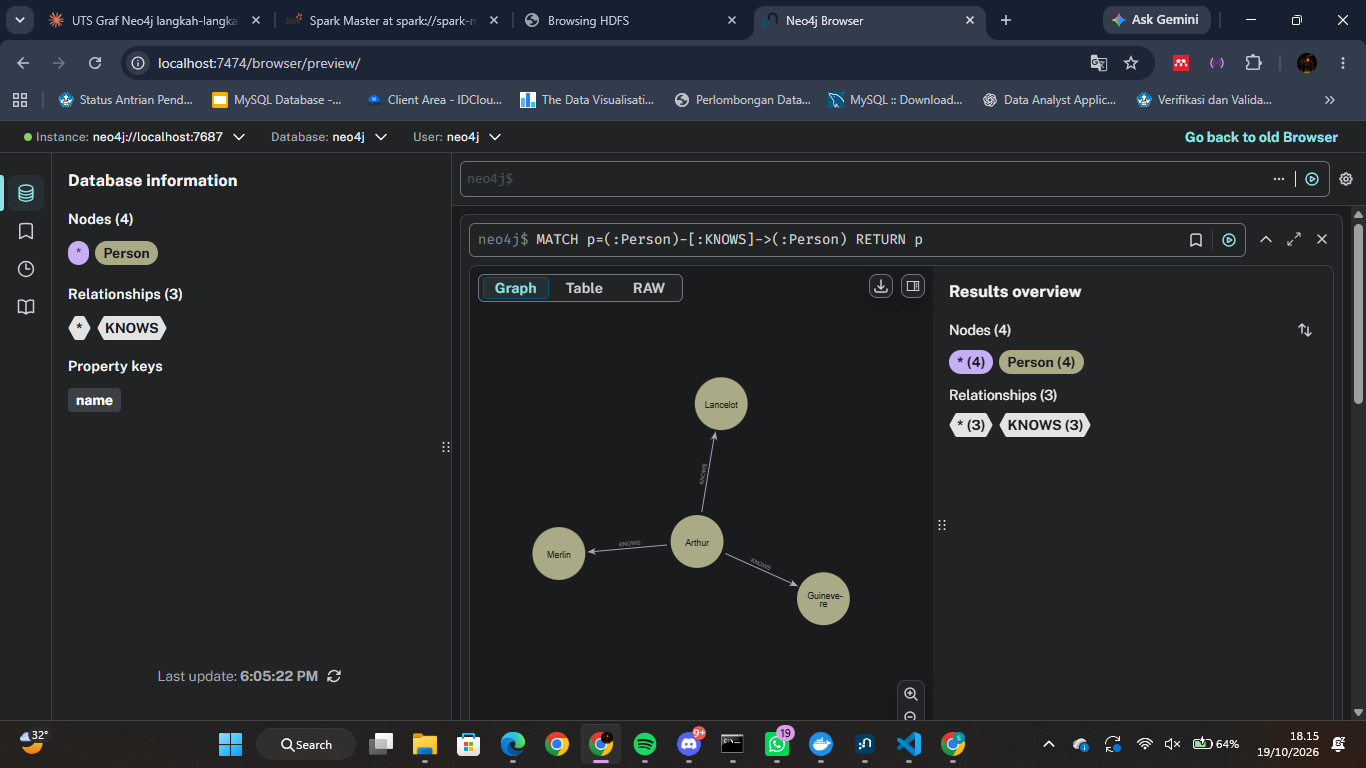

Jumlah node : 4
Jumlah edge : 3
Berarah     : True
Out-degree  : {'Arthur': 3, 'Guinevere': 0, 'Lancelot': 0, 'Merlin': 0}
In-degree   : {'Arthur': 0, 'Guinevere': 1, 'Lancelot': 1, 'Merlin': 1}


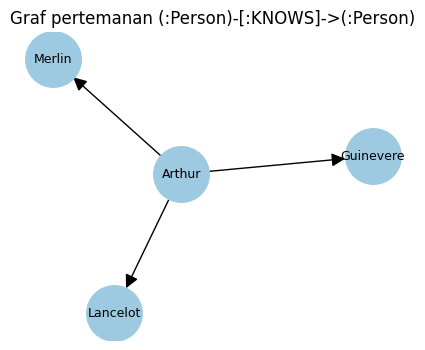

In [5]:
import networkx as nx
import matplotlib.pyplot as plt

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        edges = session.run(
            "MATCH (a:Person)-[:KNOWS]->(b:Person) RETURN a.name AS src, b.name AS dst"
        ).data()
        n_nodes = session.run("MATCH (n:Person) RETURN count(n) AS n").single()["n"]

G_friend = nx.DiGraph()
G_friend.add_edges_from((e["src"], e["dst"]) for e in edges)

print("Jumlah node :", n_nodes)
print("Jumlah edge :", len(edges))
print("Berarah     :", G_friend.is_directed())
print("Out-degree  :", dict(G_friend.out_degree()))
print("In-degree   :", dict(G_friend.in_degree()))

plt.figure(figsize=(5, 4))
pos = nx.spring_layout(G_friend, seed=42)
nx.draw_networkx(G_friend, pos, node_color="#9ecae1", node_size=1600,
                 arrows=True, arrowsize=20, font_size=9)
plt.title("Graf pertemanan (:Person)-[:KNOWS]->(:Person)")
plt.axis("off")
plt.show()

### Jawaban Pertanyaan Pendahuluan (Checkpoint) 

**1. Apa nama database yang digunakan pada tutorial ini?**

Database yang digunakan adalah **neo4j**, sesuai dengan parameter database_="neo4j" pada kode Python. Selain itu, terdapat database system yang digunakan untuk mengelola informasi dan konfigurasi database pada Neo4j.

**2. Sebutkan akses lain (sintaks DDL/DML Cypher) untuk mengakses database lain dalam satu instance!**

- SHOW DATABASES untuk melihat daftar database.
- :use namadb untuk berpindah ke database lain melalui Neo4j Browser atau cypher-shell.
- USE namadb MATCH (n) RETURN count(n) untuk menjalankan query pada database tertentu.
- CREATE DATABASE namadb untuk membuat database baru.
- DROP DATABASE namadb untuk menghapus database.
- driver.session(database="namadb") untuk memilih database melalui Python Driver.

**3. Apa jenis graf pertemanan yang telah dibuat di sini?**

- **Berarah (directed)**, karena hubungan mengarah dari Arthur ke teman-temannya.
- **Tidak berbobot (unweighted)**, karena hubungan KNOWS tidak memiliki nilai bobot.
- **Homogen**, karena hanya menggunakan satu jenis node, yaitu Person, dan satu jenis relasi, yaitu KNOWS.
- **Berbentuk bintang (star-shaped)**, karena Arthur menjadi pusat yang terhubung dengan Guinevere, Lancelot, dan Merlin tanpa hubungan balik.

#### CYPHER Total Reset

Melakukan truncate pada konten database   
**MATCH (n) DETACH DELETE n;**

*Tidak untuk shared database

In [6]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        session.run("MATCH (n) DETACH DELETE n")
        sisa = session.run("MATCH (n) RETURN count(n) AS n").single()["n"]
print("Jumlah node setelah reset:", sisa)

Jumlah node setelah reset: 0


### 1.3 Impor Data RetailRocket ke Neo4J

Dataset diunduh dari kaggle
https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset

Eksplorasi awal:

In [7]:
import pandas as pd

df = pd.read_csv("ecommerce-dataset/events.csv")
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")

print("Shape          :", df.shape)
print("Rentang waktu  :", df["dt"].min(), "s/d", df["dt"].max())
print("Visitor unik   :", df["visitorid"].nunique())
print("Item unik      :", df["itemid"].nunique())
print("Transaksi unik :", df["transactionid"].nunique())
print()
print(df["event"].value_counts())
df.head()

Shape          : (2756101, 6)
Rentang waktu  : 2015-05-03 03:00:04.384000 s/d 2015-09-18 02:59:47.788000
Visitor unik   : 1407580


Item unik      : 235061
Transaksi unik : 17672



event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


,timestamp,visitorid,event,itemid,transactionid,dt
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


In [8]:
# jumlah event per bulan, sebagai dasar menentukan periode P1 dan P2
per_bulan = (
    df.groupby([df["dt"].dt.to_period("M"), "event"]).size()
      .unstack(fill_value=0)
)
per_bulan["total"] = per_bulan.sum(axis=1)
per_bulan

event,addtocart,transaction,view,total
dt,,,,
2015-05,14369,4611,571672,590652
2015-06,15095,5043,590255,610393
2015-07,17362,5802,674820,697984
2015-08,14825,4632,533905,553362
2015-09,7681,2369,293660,303710


#### Skrip impor batch (`import_events.py`)

Skrip disusun dari potongan kode pada naskah (langkah 3–5) dengan beberapa penyesuaian dengan fungsi untuk:  
Membuat koneksi dan session Neo4j, memeriksa keberadaan file events.csv, lalu mengimpor data RetailRocket ke database Neo4j secara bertahap (batch) dengan membentuk node Visitor dan Item serta relationship berdasarkan jenis event.

In [9]:
%%writefile import_events.py
import argparse
import os
import sys

import pandas as pd
from neo4j import GraphDatabase
from tqdm import tqdm


def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database Neo4J."
    )
    parser.add_argument(
        "-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)"
    )
    parser.add_argument(
        "-p",
        "--password",
        default="password123",
        help="Password Neo4J (default: password123)",
    )
    parser.add_argument(
        "-b",
        "--bolt",
        default="neo4j://127.0.0.1:7687",
        help="Neo4J URI / Bolt (default: neo4j://127.0.0.1:7687)",
    )
    parser.add_argument(
        "-s",
        "--source",
        default="data",
        help="Direktori/folder sumber data (default: data)",
    )
    parser.add_argument(
        "-f",
        "--file",
        default="events.csv",
        help="Nama berkas CSV di dalam folder sumber (default: events.csv)",
    )
    parser.add_argument(
        "-n",
        "--batch-size",
        type=int,
        default=5000,
        help="Jumlah baris per transaksi (default: 5000)",
    )
    return parser.parse_args()


def create_constraints(session):
    session.run(
        "CREATE CONSTRAINT visitor_id IF NOT EXISTS "
        "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE"
    )
    session.run(
        "CREATE CONSTRAINT item_id IF NOT EXISTS "
        "FOR (i:Item) REQUIRE i.itemId IS UNIQUE"
    )


def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)


def main():
    args = parse_arguments()

    csv_file_path = os.path.join(args.source, args.file)

    if not os.path.exists(csv_file_path):
        print(f"Error: File '{csv_file_path}' tidak ditemukan!")
        sys.exit(1)

    try:
        driver = GraphDatabase.driver(
            args.bolt, auth=(args.user, args.password)
        )
        driver.verify_connectivity()
    except Exception as e:
        print(f"Gagal terhubung ke database: {e}")
        sys.exit(1)

    batch_size = args.batch_size

    with driver.session(database="neo4j") as session:
        create_constraints(session)

        print(f"Membaca file data dari: {csv_file_path}")
        chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

        with open(csv_file_path, encoding="utf-8") as f:
            total_rows = sum(1 for _ in f) - 1  # tanpa baris header
        total_chunks = (total_rows // batch_size) + 1

        print("Memulai proses impor data ke Neo4j...")
        for chunk in tqdm(
            chunks, total=total_chunks, desc="Mengimpor Batch Data"
        ):
            # Membersihkan data null/NaN pada transactionid
            chunk["transactionid"] = (
                chunk["transactionid"].astype("Int64").astype(str)
                .replace("<NA>", "")
            )

            records = chunk.to_dict(orient="records")
            session.write_transaction(import_batch, records)

    driver.close()
    print(f"Proses impor berhasil: {total_rows} baris.")


if __name__ == "__main__":
    main()

Overwriting import_events.py


#### Uji coba skrip impor

Skrip diuji menggunakan 10.000 data event pertama berdasarkan urutan waktu. Kolom tambahan dt dihapus agar format data sesuai dengan file events.csv asli.

In [10]:
import os

os.makedirs("data", exist_ok=True)
sampel = df.sort_values("timestamp").head(10_000).drop(columns="dt")
sampel.to_csv("data/events_sample.csv", index=False)
print(sampel.shape)
print(sampel["event"].value_counts())

(10000, 5)
event
view           9728
addtocart       211
transaction      61
Name: count, dtype: int64


In [ ]:
!"{sys.executable}" import_events.py --help

usage: import_events.py [-h] [-u USER] [-p PASSWORD] [-b BOLT] [-s SOURCE]
                        [-f FILE] [-n BATCH_SIZE]

Impor dataset RetailRocket (events.csv) ke database Neo4J.

options:
  -h, --help            show this help message and exit
  -u USER, --user USER  Username Neo4j (default: neo4j)
  -p PASSWORD, --password PASSWORD
                        Password Neo4J (default: password123)
  -b BOLT, --bolt BOLT  Neo4J URI / Bolt (default: neo4j://127.0.0.1:7687)
  -s SOURCE, --source SOURCE
                        Direktori/folder sumber data (default: data)
  -f FILE, --file FILE  Nama berkas CSV di dalam folder sumber (default:
                        events.csv)
  -n BATCH_SIZE, --batch-size BATCH_SIZE
                        Jumlah baris per transaksi (default: 5000)


In [12]:
!"{sys.executable}" import_events.py -s data -f events_sample.csv -n 5000

Membaca file data dari: data\events_sample.csv
Memulai proses impor data ke Neo4j...
Proses impor berhasil: 10000 baris.


C:\Users\Admin\Downloads\uts-graf\import_events.py:103: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()

Mengimpor Batch Data:  67%|######6   | 2/3 [00:02<00:01,  1.07s/it]


Verifikasi hasil impor:  
jumlah node per label harus sama dengan jumlah visitor/item unik pada sampel, dan jumlah relasi per tipe harus sama dengan jumlah event per jenis.

In [13]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        nodes = session.run(
            "MATCH (n) RETURN labels(n)[0] AS label, count(*) AS jumlah ORDER BY label"
        ).data()
        rels = session.run(
            "MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY relasi"
        ).data()
        constraints = session.run("SHOW CONSTRAINTS YIELD name, labelsOrTypes, properties").data()

print(pd.DataFrame(nodes), "\n")
print(pd.DataFrame(rels), "\n")
print(pd.DataFrame(constraints), "\n")
print("Pembanding dari pandas:")
print("  visitor unik :", sampel["visitorid"].nunique())
print("  item unik    :", sampel["itemid"].nunique())
print(" ", sampel["event"].value_counts().to_dict())

     label  jumlah
0     Item    6776
1  Visitor    5882 

          relasi  jumlah
0  ADDED_TO_CART     211
1         BOUGHT      61
2         VIEWED    9728 

         name labelsOrTypes   properties
0     item_id        [Item]     [itemId]
1  visitor_id     [Visitor]  [visitorId] 

Pembanding dari pandas:
  visitor unik : 5882
  item unik    : 6776
  {'view': 9728, 'addtocart': 211, 'transaction': 61}


## 2. Soal UTS

### 2.1 Wrangling dan EDA

#### No. 1 Penentuan dua periode waktu

| Fold | Periode | Durasi | 
|---|---|---|
| **P1 (training)** | 03/08/2015 – 16/08/2015 | 2 minggu | 
| **P2 (testing)** | 17/08/2015 – 30/08/2015 | 2 minggu | 

In [14]:
import numpy as np

P1 = ("2015-08-03", "2015-08-16")  # training
P2 = ("2015-08-17", "2015-08-30")  # testing


def filter_periode(data, awal, akhir):
    """Ambil event dengan awal <= waktu < (akhir + 1 hari), sehingga tanggal akhir ikut terhitung penuh."""
    batas_awal = pd.Timestamp(awal)
    batas_akhir = pd.Timestamp(akhir) + pd.Timedelta(days=1)
    return data[(data["dt"] >= batas_awal) & (data["dt"] < batas_akhir)]


df_p1 = filter_periode(df, *P1)
df_p2 = filter_periode(df, *P2)

ringkasan = pd.DataFrame({
    fold: {
        "event": len(d),
        "visitor unik": d["visitorid"].nunique(),
        "item unik": d["itemid"].nunique(),
        "view": (d["event"] == "view").sum(),
        "addtocart": (d["event"] == "addtocart").sum(),
        "transaction": (d["event"] == "transaction").sum(),
        "waktu awal": d["dt"].min(),
        "waktu akhir": d["dt"].max(),
    }
    for fold, d in [("P1 (train)", df_p1), ("P2 (test)", df_p2)]
})
ringkasan

,P1 (train),P2 (test)
event,249322,254734
visitor unik,144757,144826
item unik,73346,74048
view,240655,245503
addtocart,6682,6943
transaction,1985,2288
waktu awal,2015-08-03 00:00:01.588000,2015-08-17 00:00:00.735000
waktu akhir,2015-08-16 23:59:55.927000,2015-08-30 23:59:52.674000


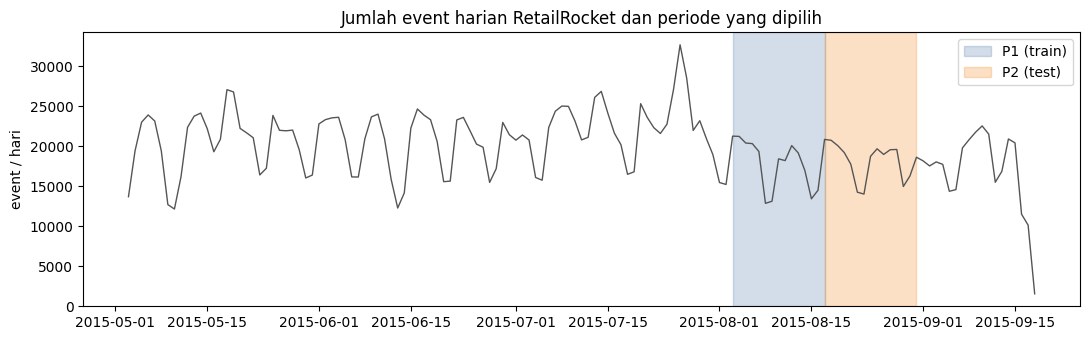

Visitor yang aktif di P1 dan P2: 5979


In [15]:
harian = df.set_index("dt").resample("D").size()

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(harian.index, harian.values, color="#555", lw=1)
ax.axvspan(pd.Timestamp(P1[0]), pd.Timestamp(P1[1]) + pd.Timedelta(days=1), color="#4c78a8", alpha=0.25, label="P1 (train)")
ax.axvspan(pd.Timestamp(P2[0]), pd.Timestamp(P2[1]) + pd.Timedelta(days=1), color="#f58518", alpha=0.25, label="P2 (test)")
ax.set_title("Jumlah event harian RetailRocket dan periode yang dipilih")
ax.set_ylabel("event / hari")
ax.legend()
plt.tight_layout()
plt.show()

irisan = set(df_p1["visitorid"]) & set(df_p2["visitorid"])
print("Visitor yang aktif di P1 dan P2:", len(irisan))

#### No. 2 Filter timestamp dan simpan ke `.csv`

In [16]:
kolom = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
df_p1[kolom].to_csv("data/events_p1.csv", index=False)
df_p2[kolom].to_csv("data/events_p2.csv", index=False)

for f in ["data/events_p1.csv", "data/events_p2.csv"]:
    cek = pd.read_csv(f)
    print(f"{f}: {cek.shape}, {pd.to_datetime(cek['timestamp'].min(), unit='ms')} s/d "
          f"{pd.to_datetime(cek['timestamp'].max(), unit='ms')}")

data/events_p1.csv: (249322, 5), 2015-08-03 00:00:01.588000 s/d 2015-08-16 23:59:55.927000


data/events_p2.csv: (254734, 5), 2015-08-17 00:00:00.735000 s/d 2015-08-30 23:59:52.674000


Subgraph yang dianalisis adalah **data P1**. Database dikosongkan dari data uji coba, lalu `events_p1.csv` diimpor dengan skrip `import_events.py`. Data P2 tidak diimpor ke graf; P2 hanya dipakai sebagai *ground truth* di bagian 2.2 agar model tidak "melihat" data uji.

In [17]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        session.run("MATCH (n) DETACH DELETE n")
        print("Node tersisa:", session.run("MATCH (n) RETURN count(n) AS n").single()["n"])

Node tersisa: 0


In [18]:
import time

t0 = time.time()
!"{sys.executable}" import_events.py -s data -f events_p1.csv -n 5000
print(f"Durasi impor: {(time.time() - t0) / 60:.1f} menit")

Membaca file data dari: data\events_p1.csvDurasi impor: 0.9 menit


C:\Users\Admin\Downloads\uts-graf\import_events.py:103: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()

Mengimpor Batch Data: 100%|##########| 50/50 [00:52<00:00,  1.04s/it]



Memulai proses impor data ke Neo4j...
Proses impor berhasil: 249322 baris.


#### No. 3 Komposisi subgraph

In [19]:
def run_query(query, **params):
    """Jalankan query baca dan kembalikan hasilnya sebagai DataFrame."""
    with GraphDatabase.driver(URI, auth=AUTH) as driver:
        with driver.session(database="neo4j") as session:
            return pd.DataFrame(session.run(query, **params).data())


komposisi_simpul = run_query("""
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah
ORDER BY jumlah DESC
""")
komposisi_relasi = run_query("""
MATCH (a)-[r]->(b)
RETURN labels(a)[0] AS dari, type(r) AS relasi, labels(b)[0] AS ke, count(*) AS jumlah
ORDER BY jumlah DESC
""")
keterlibatan = run_query("""
MATCH (v:Visitor)-[r]->(i:Item)
RETURN type(r) AS relasi, count(DISTINCT v) AS visitor, count(DISTINCT i) AS item, count(r) AS event
ORDER BY event DESC
""")

print("Komposisi simpul:\n", komposisi_simpul, "\n")
print("Komposisi relasi:\n", komposisi_relasi, "\n")
print("Keterlibatan simpul per jenis interaksi:\n", keterlibatan, "\n")
print("Total simpul :", komposisi_simpul["jumlah"].sum())
print("Total relasi :", komposisi_relasi["jumlah"].sum())
print("Cek dengan pandas P1 -> visitor:", df_p1["visitorid"].nunique(),
      "| item:", df_p1["itemid"].nunique(), "| event:", len(df_p1))

Komposisi simpul:
   jenis_simpul  jumlah
0      Visitor  144757
1         Item   73346 

Komposisi relasi:
       dari         relasi    ke  jumlah
0  Visitor         VIEWED  Item  240655
1  Visitor  ADDED_TO_CART  Item    6682
2  Visitor         BOUGHT  Item    1985 

Keterlibatan simpul per jenis interaksi:
           relasi  visitor   item   event
0         VIEWED   144334  73182  240655
1  ADDED_TO_CART     3707   4194    6682
2         BOUGHT     1075   1620    1985 

Total simpul : 218103
Total relasi : 249322
Cek dengan pandas P1 -> visitor: 144757 | item: 73346 | event: 249322


#### Persiapan VSM: bobot interaksi


In [20]:
from scipy import sparse

BOBOT_CYPHER = "CASE type(r) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 WHEN 'BOUGHT' THEN 5 END"

edges = run_query(f"""
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS visitor, i.itemId AS item, sum({BOBOT_CYPHER}) AS bobot
""")

# indeks baris/kolom matriks; diurutkan agar hasil selalu sama (reproducible)
user_ids = np.sort(edges["visitor"].unique())
item_ids = np.sort(edges["item"].unique())
user_idx = {u: k for k, u in enumerate(user_ids)}
item_idx = {i: k for k, i in enumerate(item_ids)}

rows = edges["visitor"].map(user_idx).to_numpy()
cols = edges["item"].map(item_idx).to_numpy()

X_user = sparse.csr_matrix(
    (edges["bobot"].to_numpy(dtype=float), (rows, cols)),
    shape=(len(user_ids), len(item_ids)),
)
X_item = X_user.T.tocsr()

print("Pasangan visitor-item :", len(edges))
print("Distribusi bobot      :", edges["bobot"].describe().round(2).to_dict())
edges.head()

Pasangan visitor-item : 200302
Distribusi bobot      : {'count': 200302.0, 'mean': 1.35, 'std': 1.36, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 1.0, 'max': 87.0}


,visitor,item,bobot
0,148756,248655,1
1,207378,212126,2
2,667494,305263,1
3,1135013,76126,1
4,1134074,426929,1


In [21]:
def karakteristik_vsm(X, nama_baris, nama_kolom):
    n_baris, n_kolom = X.shape
    nnz_per_baris = np.diff(X.indptr)
    dense_mb = n_baris * n_kolom * 8 / 1024**2
    sparse_mb = (X.data.nbytes + X.indices.nbytes + X.indptr.nbytes) / 1024**2
    return pd.Series({
        "shape": X.shape,
        f"jumlah vektor ({nama_baris})": n_baris,
        f"dimensi vektor (= jumlah {nama_kolom})": n_kolom,
        "elemen non-zero": X.nnz,
        "density (%)": round(100 * X.nnz / (n_baris * n_kolom), 5),
        "sparsity (%)": round(100 - 100 * X.nnz / (n_baris * n_kolom), 5),
        "rata-rata non-zero / vektor": round(nnz_per_baris.mean(), 3),
        "median non-zero / vektor": np.median(nnz_per_baris),
        "maks non-zero / vektor": nnz_per_baris.max(),
        "vektor dengan 1 non-zero (%)": round(100 * (nnz_per_baris == 1).mean(), 2),
        "memori dense (MB)": round(dense_mb, 1),
        "memori sparse CSR (MB)": round(sparse_mb, 2),
    })

In [22]:
import networkx as nx
from networkx.algorithms import bipartite

# sampel kecil yang reproducible untuk visualisasi networkx:
# satu item acak (seed 42) dengan 8-12 visitor, beserta seluruh item lain milik visitor tsb.
rng_plot = np.random.default_rng(42)
deg_item = np.diff(X_item.indptr)
deg_user = np.diff(X_user.indptr)

kandidat_seed = item_ids[(deg_item >= 8) & (deg_item <= 12)]
seed_item = int(rng_plot.choice(kandidat_seed))

s_users = [u for u in edges.loc[edges["item"] == seed_item, "visitor"].unique()
           if deg_user[user_idx[u]] <= 20]          # visitor ekstrem (bot) dibuang dari plot
s_edges = edges[edges["visitor"].isin(s_users)]

# prefiks U/I karena visitorId dan itemId bisa bernilai angka yang sama
B_s = nx.Graph()
B_s.add_nodes_from((f"U{u}" for u in s_edges["visitor"].unique()), bipartite=0)
B_s.add_nodes_from((f"I{i}" for i in s_edges["item"].unique()), bipartite=1)
B_s.add_weighted_edges_from(
    (f"U{r.visitor}", f"I{r.item}", r.bobot) for r in s_edges.itertuples()
)
s_user_nodes = [n for n, d in B_s.nodes(data=True) if d["bipartite"] == 0]
s_item_nodes = [n for n, d in B_s.nodes(data=True) if d["bipartite"] == 1]

print("Item seed sampel :", seed_item)
print("Sampel bipartit  :", len(s_user_nodes), "visitor,", len(s_item_nodes), "item,",
      B_s.number_of_edges(), "edge")

Item seed sampel : 41363
Sampel bipartit  : 8 visitor, 12 item, 19 edge


#### No. 4 VSM simpul User (Visitor)


In [23]:
vsm_user = karakteristik_vsm(X_user, "visitor", "item")
vsm_user

shape                             (144757, 73346)
jumlah vektor (visitor)                    144757
dimensi vektor (= jumlah item)              73346
elemen non-zero                            200302
density (%)                               0.00189
sparsity (%)                             99.99811
rata-rata non-zero / vektor                 1.384
median non-zero / vektor                      1.0
maks non-zero / vektor                        752
vektor dengan 1 non-zero (%)                83.88
memori dense (MB)                         81003.9
memori sparse CSR (MB)                       2.84
dtype: object

In [24]:
contoh_user = int(user_ids[np.argmax(deg_user == 3)])   # contoh visitor dengan 3 item
baris = X_user[user_idx[contoh_user]]
print(f"Vektor visitor {contoh_user} (hanya komponen non-zero dari {X_user.shape[1]} dimensi):")
print({int(item_ids[j]): v for j, v in zip(baris.indices, baris.data)})

Vektor visitor 224 (hanya komponen non-zero dari 73346 dimensi):
{168697: np.float64(6.0), 336432: np.float64(1.0), 443407: np.float64(5.0)}


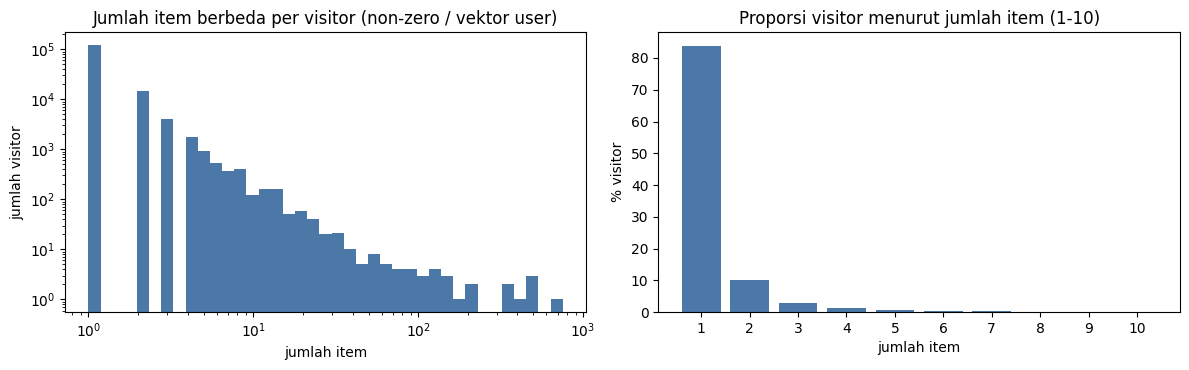

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

axes[0].hist(deg_user, bins=np.logspace(0, np.log10(deg_user.max() + 1), 40), color="#4c78a8")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_title("Jumlah item berbeda per visitor (non-zero / vektor user)")
axes[0].set_xlabel("jumlah item"); axes[0].set_ylabel("jumlah visitor")

nilai, frek = np.unique(deg_user, return_counts=True)
axes[1].bar([str(v) for v in nilai[:10]], frek[:10] / frek.sum() * 100, color="#4c78a8")
axes[1].set_title("Proporsi visitor menurut jumlah item (1-10)")
axes[1].set_xlabel("jumlah item"); axes[1].set_ylabel("% visitor")
plt.tight_layout()
plt.show()

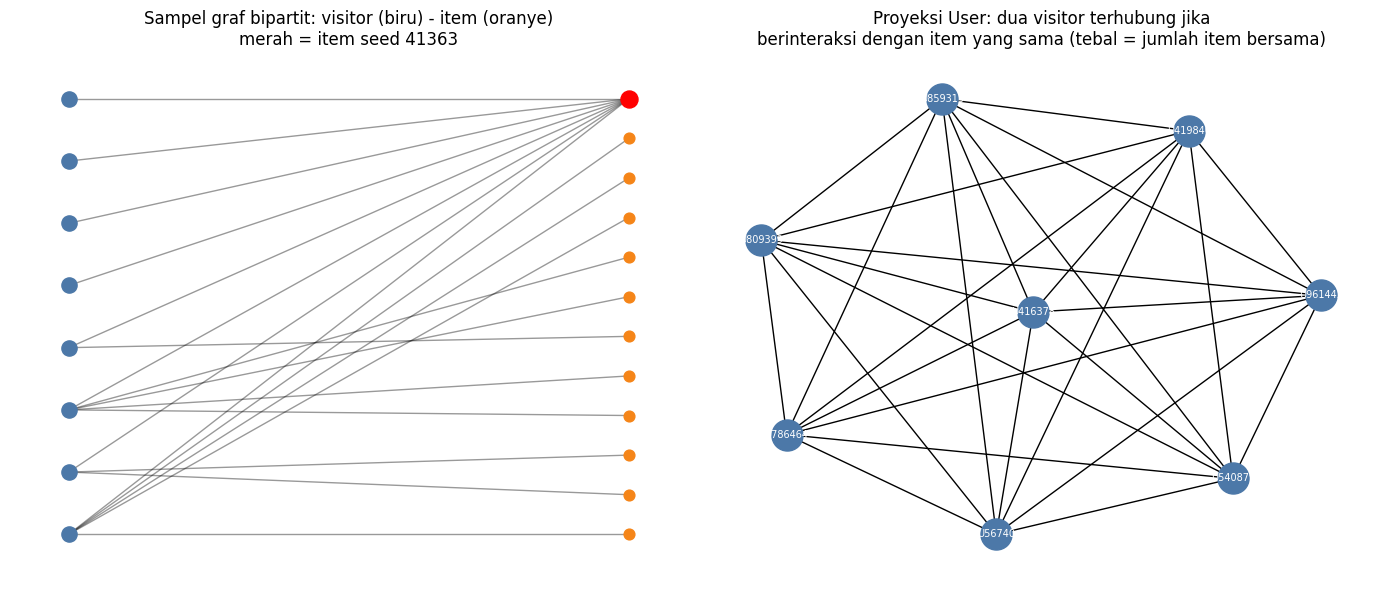

Proyeksi user (sampel): 8 node, 28 edge, density 1.0


In [26]:
G_user_s = bipartite.weighted_projected_graph(B_s, s_user_nodes)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

pos_b = nx.bipartite_layout(B_s, s_user_nodes)
nx.draw_networkx_nodes(B_s, pos_b, nodelist=s_user_nodes, node_color="#4c78a8", node_size=120, ax=axes[0])
nx.draw_networkx_nodes(B_s, pos_b, nodelist=s_item_nodes, node_color="#f58518", node_size=60, ax=axes[0])
nx.draw_networkx_edges(B_s, pos_b, alpha=0.4, ax=axes[0])
nx.draw_networkx_nodes(B_s, pos_b, nodelist=[f"I{seed_item}"], node_color="red", node_size=150, ax=axes[0])
axes[0].set_title(f"Sampel graf bipartit: visitor (biru) - item (oranye)\nmerah = item seed {seed_item}")
axes[0].axis("off")

pos_u = nx.spring_layout(G_user_s, seed=42)
lebar = [G_user_s[a][b]["weight"] for a, b in G_user_s.edges()]
nx.draw_networkx(G_user_s, pos_u, node_color="#4c78a8", node_size=500, font_size=7,
                 font_color="white", width=lebar, ax=axes[1])
axes[1].set_title("Proyeksi User: dua visitor terhubung jika\nberinteraksi dengan item yang sama (tebal = jumlah item bersama)")
axes[1].axis("off")
plt.tight_layout()
plt.show()

print("Proyeksi user (sampel):", G_user_s.number_of_nodes(), "node,",
      G_user_s.number_of_edges(), "edge, density", round(nx.density(G_user_s), 3))

**Karakteristik VSM User**

Setiap visitor diubah menjadi vektor bobot interaksi terhadap semua item (view = 1, addtocart = 3, transaction = 5, tidak berinteraksi = 0). Semua vektor disusun menjadi matriks **User × Item**.

- **Shape (144.757 × 73.346):** ada 144.757 vektor visitor, masing-masing berdimensi 73.346 (jumlah item).
- **Sangat sparse:** hanya 200.302 sel yang terisi (density 0,00189%, sparsity 99,998%). Karena itu matriks disimpan dalam format sparse CSR (2,84 MB), bukan dense (± 79 GB).
- **Contoh vektor visitor 224:** {168697: 6, 336432: 1, 443407: 5}, yaitu hanya 3 dari 73.346 dimensi yang terisi. Bobot besar (5–6) menunjukkan minat kuat, misalnya membeli.
- **Distribusi long-tail (histogram):** median hanya 1 item per visitor, dan **83,88% visitor hanya menyentuh 1 item**. Ada segelintir visitor ekstrem hingga 752 item, kemungkinan bot.
- **Plot networkx (sampel 8 visitor dari item 41363):** proyeksi User menghasilkan 8 node dan 28 edge dengan **density 1,0** (graf lengkap). Semua visitor saling terhubung hanya karena melihat satu item yang sama.

Jadi, vektor user berdimensi besar tetapi hampir kosong, dan proyeksinya cenderung membentuk *clique*, sehingga sulit membedakan visitor mana yang beneran mirip.

#### No. 5 VSM simpul Item

In [27]:
vsm_item = karakteristik_vsm(X_item, "item", "visitor")
vsm_item

shape                                (73346, 144757)
jumlah vektor (item)                           73346
dimensi vektor (= jumlah visitor)             144757
elemen non-zero                               200302
density (%)                                  0.00189
sparsity (%)                                99.99811
rata-rata non-zero / vektor                    2.731
median non-zero / vektor                         1.0
maks non-zero / vektor                          1291
vektor dengan 1 non-zero (%)                   55.96
memori dense (MB)                            81003.9
memori sparse CSR (MB)                          2.57
dtype: object

In [28]:
contoh_item = int(item_ids[np.argmax(deg_item == 3)])   # contoh item dengan 3 visitor
baris = X_item[item_idx[contoh_item]]
print(f"Vektor item {contoh_item} (hanya komponen non-zero dari {X_item.shape[1]} dimensi):")
print({int(user_ids[j]): v for j, v in zip(baris.indices, baris.data)})

Vektor item 6 (hanya komponen non-zero dari 144757 dimensi):
{712131: np.float64(1.0), 713551: np.float64(1.0), 771857: np.float64(2.0)}


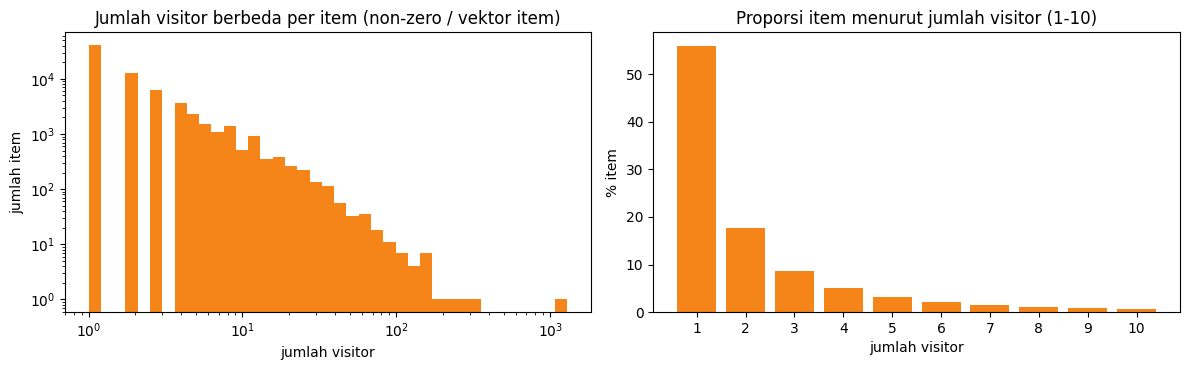

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

axes[0].hist(deg_item, bins=np.logspace(0, np.log10(deg_item.max() + 1), 40), color="#f58518")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_title("Jumlah visitor berbeda per item (non-zero / vektor item)")
axes[0].set_xlabel("jumlah visitor"); axes[0].set_ylabel("jumlah item")

nilai, frek = np.unique(deg_item, return_counts=True)
axes[1].bar([str(v) for v in nilai[:10]], frek[:10] / frek.sum() * 100, color="#f58518")
axes[1].set_title("Proporsi item menurut jumlah visitor (1-10)")
axes[1].set_xlabel("jumlah visitor"); axes[1].set_ylabel("% item")
plt.tight_layout()
plt.show()

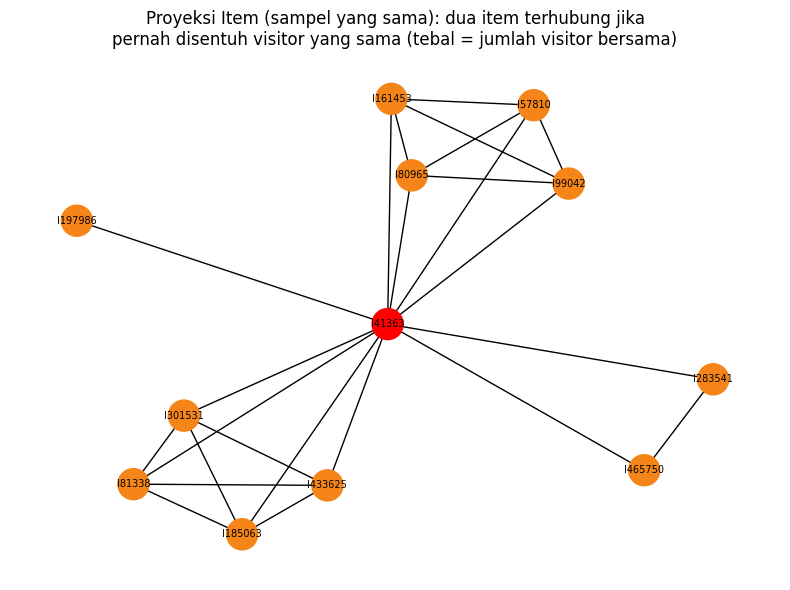

Proyeksi item (sampel): 12 node, 24 edge, density 0.364


In [30]:
G_item_s = bipartite.weighted_projected_graph(B_s, s_item_nodes)

fig, ax = plt.subplots(figsize=(8, 6))
pos_i = nx.spring_layout(G_item_s, seed=42)
lebar = [G_item_s[a][b]["weight"] for a, b in G_item_s.edges()]
warna = ["red" if n == f"I{seed_item}" else "#f58518" for n in G_item_s.nodes()]
nx.draw_networkx(G_item_s, pos_i, node_color=warna, node_size=500, font_size=7, width=lebar, ax=ax)
ax.set_title("Proyeksi Item (sampel yang sama): dua item terhubung jika\n"
             "pernah disentuh visitor yang sama (tebal = jumlah visitor bersama)")
ax.axis("off")
plt.tight_layout()
plt.show()

print("Proyeksi item (sampel):", G_item_s.number_of_nodes(), "node,",
      G_item_s.number_of_edges(), "edge, density", round(nx.density(G_item_s), 3))

**Karakteristik VSM Item**

Setiap item diubah menjadi vektor bobot interaksi dari semua visitor (view = 1, addtocart = 3, transaction = 5, tidak berinteraksi = 0). Matriksnya adalah **Item × User**, yaitu transpose dari matriks VSM User.

- **Shape (73.346 × 144.757):** ada 73.346 vektor item, masing-masing berdimensi 144.757 (jumlah visitor).
- **Sangat sparse:** jumlah sel terisi sama dengan VSM User (200.302; density 0,00189%, sparsity 99,998%), karena matriksnya hanya dibalik. Disimpan dalam format sparse CSR (2,57 MB), bukan dense (± 79 GB).
- **Contoh vektor item 6:** {712131: 1, 713551: 1, 771857: 2}, yaitu item ini disentuh oleh 3 visitor. Dua visitor hanya melihat sekali, satu visitor melihat dua kali.
- **Distribusi long-tail (histogram):** rata-rata 2,73 visitor per item, **2× lebih padat** dibanding vektor user (1,38). Item yang hanya punya 1 visitor sebanyak 55,96% (vs 83,88% pada user), sekitar 18% punya 2 visitor dan 9% punya 3 visitor. Ada segelintir item sangat populer hingga 1.291 visitor.
- **Plot networkx (sampel yang sama dengan VSM User):** proyeksi Item menghasilkan 12 node dan 24 edge dengan **density 0,364**, jauh di bawah proyeksi User (1,0). Item seed 41363 (merah) menjadi penghubung, dan terlihat **kelompok item yang jelas**, misalnya {161453, 57810, 80965, 99042} dan {301531, 81338, 433625, 185063}, yaitu item-item yang sering dilihat oleh visitor yang sama.

Jadi, vektor item lebih informatif daripada vektor user (lebih banyak komponen terisi per vektor), dan proyeksinya membentuk struktur kelompok yang bermakna, cocok untuk rekomendasi "pengunjung yang melihat item ini juga melihat …"


#### No. 6 Perbandingan proyeksi User vs Item

In [31]:
from scipy.sparse.csgraph import connected_components
from sklearn.preprocessing import normalize


def statistik_proyeksi(X):
    biner = (X > 0).astype(np.float32)

    t0 = time.perf_counter()
    C = (biner @ biner.T).tocsr()
    C.setdiag(0)
    C.eliminate_zeros()
    waktu_proyeksi = time.perf_counter() - t0

    t0 = time.perf_counter()
    Xn = normalize(X, norm="l2", axis=1)
    S = (Xn @ Xn.T).tocsr()
    waktu_cosine = time.perf_counter() - t0

    n = C.shape[0]
    deg = np.diff(C.indptr)
    n_komp, label = connected_components(C, directed=False)
    return pd.Series({
        "jumlah simpul": n,
        "jumlah edge": C.nnz // 2,
        "density (%)": round(100 * C.nnz / (n * (n - 1)), 5),
        "rata-rata degree": round(deg.mean(), 2),
        "maks degree": deg.max(),
        "simpul terisolasi (%)": round(100 * (deg == 0).mean(), 2),
        "simpul punya >= 5 tetangga (%)": round(100 * (deg >= 5).mean(), 2),
        "jumlah komponen": n_komp,
        "komponen terbesar (% simpul)": round(100 * np.bincount(label).max() / n, 2),
        "waktu proyeksi (detik)": round(waktu_proyeksi, 3),
        "waktu cosine semua pasangan (detik)": round(waktu_cosine, 3),
        "memori matriks similarity (MB)": round((S.data.nbytes + S.indices.nbytes + S.indptr.nbytes) / 1024**2, 1),
    })


perbandingan = pd.DataFrame({
    "Proyeksi User": statistik_proyeksi(X_user),
    "Proyeksi Item": statistik_proyeksi(X_item),
})
perbandingan

,Proyeksi User,Proyeksi Item
jumlah simpul,1.447570e+05,7.334600e+04
jumlah edge,1.931045e+06,1.169625e+06
density (%),1.843000e-02,4.348000e-02
rata-rata degree,2.668000e+01,3.189000e+01
maks degree,7.155000e+03,3.047000e+03
simpul terisolasi (%),1.991000e+01,5.197000e+01
simpul punya >= 5 tetangga (%),4.711000e+01,2.313000e+01
jumlah komponen,4.155900e+04,4.155900e+04
komponen terbesar (% simpul),5.147000e+01,3.648000e+01
waktu proyeksi (detik),1.690000e-01,6.900000e-02


**Perbandingan Proyeksi User vs Item**

| Aspek | Proyeksi User | Proyeksi Item | Lebih baik |
|---|---|---|---|
| Jumlah simpul | 144.757 | 73.346 | Item (± setengahnya) |
| Jumlah edge | 1,93 juta | 1,17 juta | Item (−39%) |
| Maks degree | 7.155 | 3.047 | Item (hub lebih kecil) |
| Waktu proyeksi | 0,169 s | 0,069 s | Item (± 2,5× lebih cepat) |
| Waktu cosine | 0,164 s | 0,063 s | Item (± 2,6× lebih cepat) |
| Memori similarity | 46,4 MB | 27,9 MB | Item (−40%) |
| Non-zero per vektor (no. 4–5) | 1,38 | 2,73 | Item (2× lebih informatif) |
| Simpul terisolasi | 19,9% | 52,0% | User |

**Efisiensi:** proyeksi Item lebih unggul. Simpulnya setengah, edge-nya lebih sedikit, perhitungannya ± 2,5× lebih cepat, dan memorinya lebih hemat. Jumlah item juga relatif stabil, sedangkan visitor terus bertambah, sehingga similarity item cukup dihitung sekali lalu disimpan.

**Efektivitas:** proyeksi Item juga lebih unggul. 83,88% visitor hanya punya 1 item, sehingga cosine antar-visitor hampir selalu bernilai 0 atau 1 dan tidak bisa membedakan mana yang lebih mirip. Proyeksi User memang terlihat lebih terhubung (47% simpul punya ≥ 5 tetangga), tetapi itu karena terbentuk *clique*: semua visitor yang melihat satu item populer langsung saling terhubung (density sampel 1,0). Sebaliknya, proyeksi Item membentuk kelompok item yang bermakna (density sampel 0,364).

**Catatan:** proyeksi Item punya lebih banyak simpul terisolasi (52%), yaitu item yang hanya dilihat visitor yang tidak menyentuh item lain. Item seperti ini memang tidak punya data interaksi bersama, jadi tidak bisa dihubungkan oleh metode apa pun. Jumlah komponen kedua proyeksi sama (41.559), karena keduanya berasal dari graf bipartit yang sama, sehingga tidak ada informasi keterhubungan yang hilang.

**Kesimpulan:** **proyeksi Item lebih baik** (lebih efisien dan lebih efektif), sehingga dipakai untuk perhitungan similarity (no. 7) dan rekomendasi KNN (2.2).


#### No. 7 Similarity pada graf terproyeksi (Item)

In [32]:
from sklearn.metrics.pairwise import cosine_similarity

acuan = run_query("""
MATCH (v:Visitor)-[:BOUGHT]->(i:Item)
RETURN i.itemId AS item, count(*) AS jumlah_beli, count(DISTINCT v) AS pembeli
ORDER BY jumlah_beli DESC, item ASC
LIMIT 5
""")
print("Item paling banyak dibeli di P1:\n", acuan, "\n")

REF_ITEM = int(acuan.loc[0, "item"])
print("Record acuan  :", REF_ITEM)
print("Jumlah visitor:", deg_item[item_idx[REF_ITEM]])

# perhitungan similarity dengan Python (sklearn) terhadap semua item lain
sim_ref = cosine_similarity(X_item[item_idx[REF_ITEM]], X_item).ravel()
sim_ref[item_idx[REF_ITEM]] = -1   # abaikan dirinya sendiri

top5_py = (
    pd.DataFrame({"item": item_ids, "cosine": sim_ref})
      .sort_values(["cosine", "item"], ascending=[False, True])
      .head(5)
      .reset_index(drop=True)
)
print("\nTop-5 item paling mirip (Python / sklearn):")
top5_py

Item paling banyak dibeli di P1:
      item  jumlah_beli  pembeli
0  461686           24       24
1  441852           10       10
2  119736            9        5
3    9877            8        8
4  248455            7        7 

Record acuan  : 461686
Jumlah visitor: 200

Top-5 item paling mirip (Python / sklearn):


,item,cosine
0,218794,0.415291
1,171878,0.399836
2,10572,0.320557
3,387732,0.279313
4,32581,0.276038


In [33]:
CYPHER_TOP5 = """
MATCH (ref:Item {itemId: $ref})<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
WITH ref, v, sum(CASE type(r1) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 WHEN 'BOUGHT' THEN 5.0 END) AS w1
WITH ref, collect({v: v, w: w1}) AS vektor_ref, sqrt(sum(w1 * w1)) AS norm_ref
UNWIND vektor_ref AS e
WITH ref, norm_ref, e.v AS v, e.w AS w1
MATCH (v)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(other:Item)
WHERE other <> ref
WITH ref, norm_ref, other, v, w1,
     sum(CASE type(r2) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 WHEN 'BOUGHT' THEN 5.0 END) AS w2
WITH ref, norm_ref, other, sum(w1 * w2) AS dot
CALL {
  WITH other
  MATCH (other)<-[r3:VIEWED|ADDED_TO_CART|BOUGHT]-(u:Visitor)
  WITH u, sum(CASE type(r3) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 WHEN 'BOUGHT' THEN 5.0 END) AS w
  RETURN sqrt(sum(w * w)) AS norm_other
}
RETURN other.itemId AS item, dot / (norm_ref * norm_other) AS cosine
ORDER BY cosine DESC, item ASC
LIMIT 5
"""

top5_cypher = run_query(CYPHER_TOP5, ref=REF_ITEM)
print("Top-5 dari CYPHER:")
print(top5_cypher, "\n")

cek = top5_cypher.merge(top5_py, on="item", suffixes=("_cypher", "_python"))
cek["selisih"] = (cek["cosine_cypher"] - cek["cosine_python"]).abs()
print("Perbandingan Cypher vs Python:")
print(cek)
print("\nHasil identik:", list(top5_cypher["item"]) == list(top5_py["item"])
      and np.allclose(top5_cypher["cosine"], top5_py["cosine"]))

Top-5 dari CYPHER:
     item    cosine
0  218794  0.415291
1  171878  0.399836
2   10572  0.320557
3  387732  0.279313
4   32581  0.276038 

Perbandingan Cypher vs Python:
     item  cosine_cypher  cosine_python       selisih
0  218794       0.415291       0.415291  5.551115e-17
1  171878       0.399836       0.399836  5.551115e-17
2   10572       0.320557       0.320557  5.551115e-17
3  387732       0.279313       0.279313  0.000000e+00
4   32581       0.276038       0.276038  0.000000e+00

Hasil identik: True


**Perhitungan Similarity (Proyeksi Item)**

Similarity dihitung dengan **cosine similarity** antar vektor item:  
Cosine mengukur **kemiripan pola** visitor yang menyentuh dua item, bukan jumlahnya, sehingga item populer tidak otomatis mirip dengan semua item. Nilainya 0 (tidak mirip) sampai 1 (sangat mirip).

**Record acuan:** item **461686**, item yang paling banyak dibeli di P1 (24 kali oleh 24 pembeli, total 200 visitor). Item terlaris dipilih karena relevan secara bisnis dan punya cukup banyak visitor sehingga hasil similarity-nya bermakna.

**(a) 5 record dengan similarity tertinggi**

| Peringkat | Item | Cosine |
|---|---|---|
| 1 | 218794 | 0,4153 |
| 2 | 171878 | 0,3998 |
| 3 | 10572 | 0,3206 |
| 4 | 387732 | 0,2793 |
| 5 | 32581 | 0,2760 |

Cara kerja query Cypher:
1. Ambil semua visitor item acuan beserta bobotnya, lalu hitung panjang (norm) vektornya.
2. Cari item lain yang disentuh visitor yang sama, lalu hitung *dot product*-nya.
3. Hitung norm vektor setiap item kandidat dengan subquery `CALL { }`.
4. Hitung cosine = dot / (norm acuan × norm kandidat), urutkan dari yang terbesar, ambil 5 teratas (`LIMIT 5`).

Hasil Cypher **identik** dengan perhitungan Python (sklearn), baik urutan maupun nilainya. Selisih terbesar hanya ≈ 5,6 × 10⁻¹⁷ akibat pembulatan desimal komputer, sehingga perhitungan dipastikan benar.

**(b) Menulis similarity ke graf**

Kelima nilai cosine disimpan ke Neo4j sebagai relasi baru `(:Item)-[:SIMILAR {score}]->(:Item)` dari item 461686 ke 5 item termiripnya. `MERGE` mencegah relasi dobel jika dijalankan ulang, dan `SET` mengisi nilai `score`.

Query baca ulang menunjukkan **5 relasi SIMILAR** tersimpan dengan nilai yang sama persis dengan hasil (a). Sekarang item acuan terhubung **langsung** ke item-item yang mirip, sehingga rekomendasi cukup menelusuri satu langkah `-[:SIMILAR]->` tanpa menghitung ulang similarity.


#### No. 8 (bagian 1) Kondisi graf **sebelum** similarity ditulis


In [34]:
TOP5_ITEMS = [int(x) for x in top5_cypher["item"]]

CYPHER_SEBELUM = """
MATCH (ref:Item {itemId: $ref})<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
      -[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(o:Item)
WHERE o.itemId IN $top5
RETURN DISTINCT v.visitorId AS visitor, type(r1) AS rel_ref, o.itemId AS item, type(r2) AS rel_item
"""
CYPHER_SIMILAR = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR]->(b:Item)
RETURN a.itemId AS dari, b.itemId AS ke, s.score AS score
ORDER BY score DESC
"""

jalur_sebelum = run_query(CYPHER_SEBELUM, ref=REF_ITEM, top5=TOP5_ITEMS)
similar_sebelum = run_query(CYPHER_SIMILAR, ref=REF_ITEM)
relasi_sebelum = run_query("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY relasi")

print("Jumlah relasi SIMILAR dari item acuan:", len(similar_sebelum))
print("\nTipe relasi di seluruh graf (sebelum):\n", relasi_sebelum)
print("\nJalur item acuan -> visitor -> item mirip:", len(jalur_sebelum), "baris")
jalur_sebelum.head(10)

Jumlah relasi SIMILAR dari item acuan: 0

Tipe relasi di seluruh graf (sebelum):
           relasi  jumlah
0  ADDED_TO_CART    6682
1         BOUGHT    1985
2         VIEWED  240655

Jalur item acuan -> visitor -> item mirip: 205 baris


,visitor,rel_ref,item,rel_item
0,942592,ADDED_TO_CART,171878,VIEWED
1,942592,ADDED_TO_CART,171878,ADDED_TO_CART
2,464410,ADDED_TO_CART,218794,BOUGHT
3,464410,ADDED_TO_CART,32581,BOUGHT
4,464410,ADDED_TO_CART,32581,VIEWED
5,464410,ADDED_TO_CART,218794,VIEWED
6,464410,ADDED_TO_CART,32581,ADDED_TO_CART
7,464410,ADDED_TO_CART,218794,ADDED_TO_CART
8,1110822,ADDED_TO_CART,218794,BOUGHT
9,1110822,ADDED_TO_CART,218794,ADDED_TO_CART


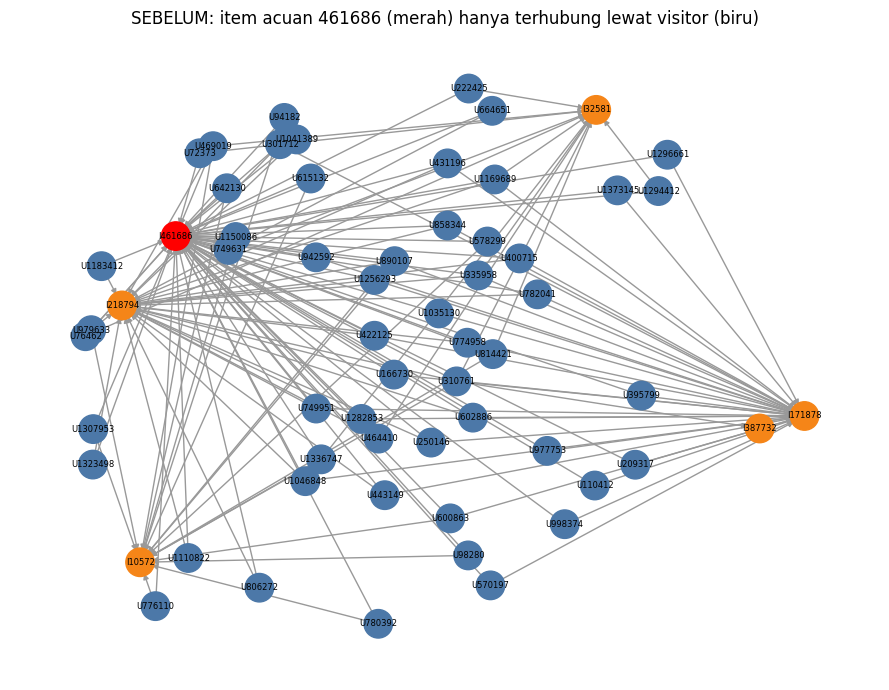

In [35]:
def gambar_graf_acuan(jalur, similar, judul, ax):
    G = nx.DiGraph()
    ref = f"I{REF_ITEM}"
    for r in jalur.itertuples():
        G.add_edge(f"U{r.visitor}", ref, tipe=r.rel_ref)
        G.add_edge(f"U{r.visitor}", f"I{r.item}", tipe=r.rel_item)
    for r in similar.itertuples():
        G.add_edge(f"I{r.dari}", f"I{r.ke}", tipe="SIMILAR", score=r.score)
    for it in TOP5_ITEMS:
        G.add_node(f"I{it}")

    pos = nx.spring_layout(G, seed=7, k=0.9)
    warna = ["red" if n == ref else "#f58518" if n.startswith("I") else "#4c78a8" for n in G.nodes()]
    interaksi = [(a, b) for a, b, d in G.edges(data=True) if d["tipe"] != "SIMILAR"]
    sim = [(a, b) for a, b, d in G.edges(data=True) if d["tipe"] == "SIMILAR"]

    nx.draw_networkx_nodes(G, pos, node_color=warna, node_size=420, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=6, ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=interaksi, edge_color="#999", arrows=True, arrowsize=8, ax=ax)
    if sim:
        nx.draw_networkx_edges(G, pos, edgelist=sim, edge_color="crimson", width=2.5,
                               style="dashed", arrows=True, arrowsize=14, ax=ax)
        nx.draw_networkx_edge_labels(
            G, pos, edge_labels={(a, b): f"{G[a][b]['score']:.3f}" for a, b in sim},
            font_size=7, font_color="crimson", ax=ax)
    ax.set_title(judul)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(9, 7))
gambar_graf_acuan(jalur_sebelum, similar_sebelum,
                  f"SEBELUM: item acuan {REF_ITEM} (merah) hanya terhubung lewat visitor (biru)", ax)
plt.tight_layout()
plt.show()

##### (b) Menuliskan kembali nilai similarity ke graf

In [36]:
CYPHER_TULIS = """
UNWIND $rows AS row
MATCH (a:Item {itemId: $ref}), (b:Item {itemId: row.item})
MERGE (a)-[s:SIMILAR]->(b)
SET s.score = row.cosine, s.metric = 'cosine', s.periode = 'P1'
RETURN a.itemId AS dari, b.itemId AS ke, s.score AS score
"""

rows = [{"item": int(r.item), "cosine": float(r.cosine)} for r in top5_cypher.itertuples()]
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        hasil_tulis = session.write_transaction(
            lambda tx: tx.run(CYPHER_TULIS, rows=rows, ref=REF_ITEM).data()
        )
print("Relasi yang ditulis:")
pd.DataFrame(hasil_tulis)

Relasi yang ditulis:


,dari,ke,score
0,461686,218794,0.415291
1,461686,171878,0.399836
2,461686,10572,0.320557
3,461686,387732,0.279313
4,461686,32581,0.276038


In [37]:
# membaca kembali relasi SIMILAR yang sudah tersimpan di graf
similar_sesudah = run_query(CYPHER_SIMILAR, ref=REF_ITEM)
similar_sesudah

,dari,ke,score
0,461686,218794,0.415291
1,461686,171878,0.399836
2,461686,10572,0.320557
3,461686,387732,0.279313
4,461686,32581,0.276038


#### No. 8 (bagian 2) Kondisi graf **sesudah** similarity ditulis

Tipe relasi di seluruh graf:
          relasi  jumlah_sebelum  jumlah_sesudah
0  ADDED_TO_CART            6682            6682
1         BOUGHT            1985            1985
2        SIMILAR               0               5
3         VIEWED          240655          240655


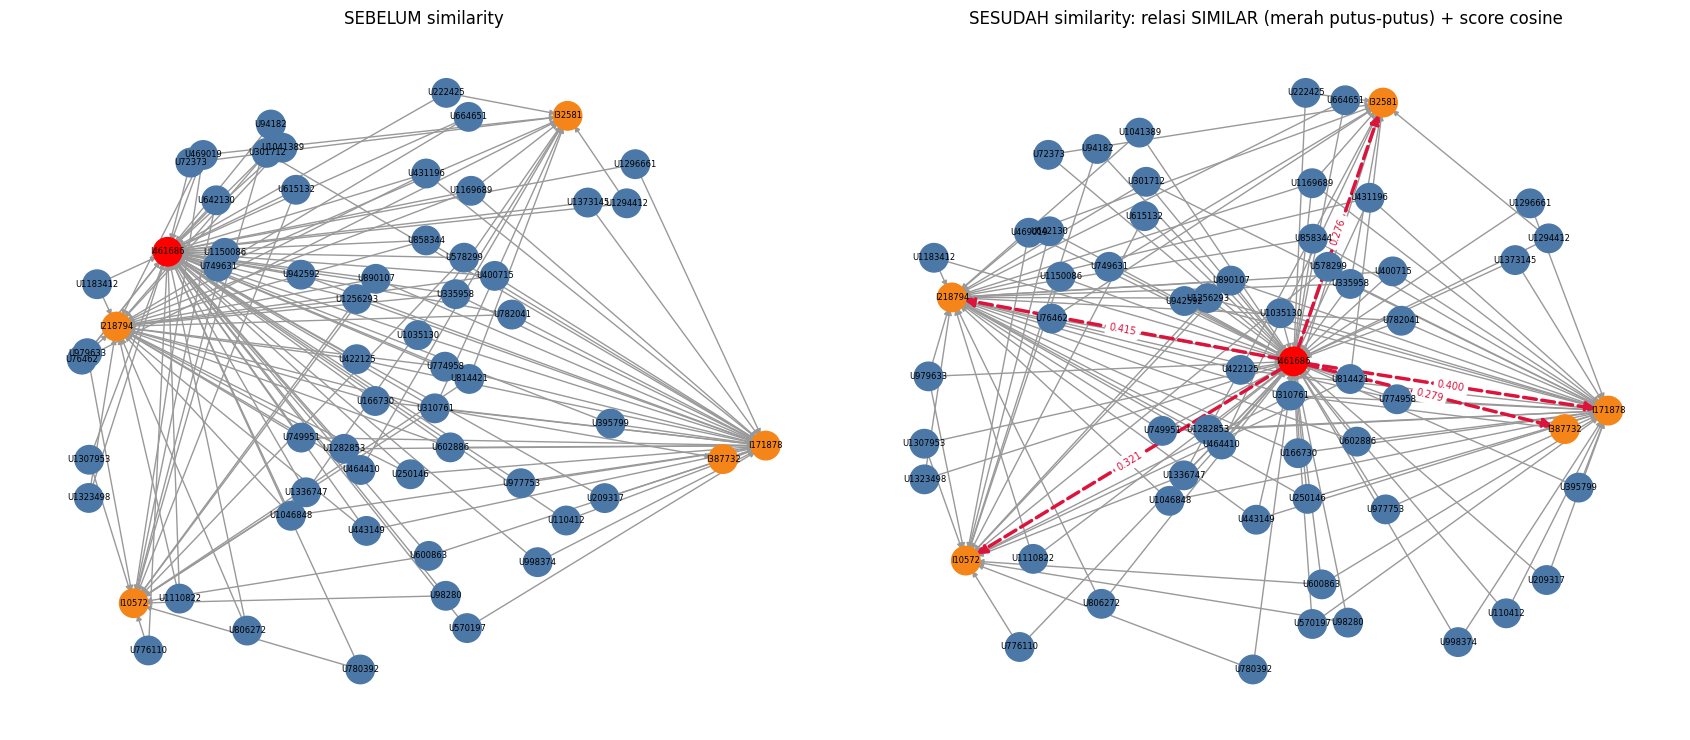

In [38]:
relasi_sesudah = run_query("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY relasi")
print("Tipe relasi di seluruh graf:")
print(relasi_sebelum.merge(relasi_sesudah, on="relasi", how="outer", suffixes=("_sebelum", "_sesudah"))
      .fillna(0).astype({"jumlah_sebelum": int, "jumlah_sesudah": int}))

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
gambar_graf_acuan(jalur_sebelum, similar_sebelum, "SEBELUM similarity", axes[0])
gambar_graf_acuan(jalur_sebelum, similar_sesudah,
                  "SESUDAH similarity: relasi SIMILAR (merah putus-putus) + score cosine", axes[1])
plt.tight_layout()
plt.show()

### 2.2 Analytics

Berdasarkan no. 6, rekomendasi dibuat dengan **item-based KNN**. Idenya sederhana: *"jika kamu menyukai item A, kamu mungkin juga menyukai item yang mirip dengan A."*

**Langkah-langkahnya:**

1. **Lihat riwayat user.** Ambil semua item yang pernah disentuh user di P1, beserta bobot minatnya: dilihat = 1, masuk keranjang = 3, dibeli = 5.
2. **Cari tetangga terdekat (k = 5).** Untuk setiap item di riwayat itu, cari **5 item yang paling mirip** berdasarkan cosine similarity (hasil no. 7).
3. **Beri skor setiap kandidat.** Skor = bobot item asal × nilai kemiripan. Jika satu kandidat muncul sebagai tetangga dari beberapa item riwayat, skornya dijumlahkan:

$$\text{skor}(j) = \sum (\text{bobot item asal} \times \text{cosine dengan item } j)$$

   Dengan begitu, item yang mirip dengan produk yang **dibeli** user mendapat skor lebih tinggi daripada item yang mirip dengan produk yang hanya **dilihat**.
4. **Buang item yang sudah pernah disentuh**, karena tidak perlu diiklankan lagi.
5. **Ambil 3 item dengan skor tertinggi** sebagai item yang diiklankan. Jika skornya sama, item dengan ID lebih kecil didahulukan agar hasilnya selalu sama setiap kali dijalankan.

**Contoh singkat:** user melihat item A sekali (bobot 1) dan item B empat kali (bobot 4). Item X mirip dengan A (cosine 0,73) dan mirip dengan B (cosine 0,58), sehingga skor X = 1 × 0,73 + 4 × 0,58 = **3,05**. Item X mendapat skor tinggi karena mirip dengan **dua** item yang disukai user, terutama item B yang paling sering dilihat.


#### No. 1(a) Skrip Python rekomendasi KNN

In [ ]:
X_item_norm = normalize(X_item, norm="l2", axis=1)
S_item = (X_item_norm @ X_item_norm.T).tocsr()
S_item.setdiag(0)    
S_item.eliminate_zeros()

K = 5      
N_REKOM = 3  


def tetangga_knn(item_id, k=K):
    """k item paling mirip (cosine) dengan item_id: list of (item_id, similarity)."""
    baris = S_item[item_idx[item_id]]
    urutan = np.lexsort((item_ids[baris.indices], -baris.data))[:k]   
    return [(int(item_ids[baris.indices[j]]), float(baris.data[j])) for j in urutan]


def riwayat_user(user_id):
    """Item yang disentuh user di P1 beserta bobot interaksinya: dict item_id -> bobot."""
    baris = X_user[user_idx[user_id]]
    return {int(item_ids[j]): float(w) for j, w in zip(baris.indices, baris.data)}


def rekomendasi_knn(user_id, k=K, n=N_REKOM, detail=False):
    riwayat = riwayat_user(user_id)
    skor, jejak = {}, []
    for item_asal, bobot in riwayat.items():
        for kandidat, sim in tetangga_knn(item_asal, k):
            jejak.append({"item_asal": item_asal, "bobot_asal": bobot, "tetangga": kandidat,
                          "cosine": sim, "sudah_disentuh": kandidat in riwayat,
                          "kontribusi": bobot * sim})
            if kandidat in riwayat:
                continue
            skor[kandidat] = skor.get(kandidat, 0.0) + bobot * sim
    hasil = sorted(skor.items(), key=lambda t: (-t[1], t[0]))
    rekom = pd.DataFrame(hasil[:n], columns=["item", "skor"])
    rekom.index = rekom.index + 1
    rekom.index.name = "peringkat"
    if detail:
        return rekom, pd.DataFrame(jejak), hasil
    return rekom


print("Matriks similarity item:", S_item.shape, "| pasangan non-zero:", S_item.nnz)

Matriks similarity item: (73346, 73346) | pasangan non-zero: 2339250


In [40]:
SEED = 42

truth_p2 = df_p2.groupby("visitorid")["itemid"].apply(lambda s: set(int(x) for x in s))

kandidat_user = sorted(set(int(u) for u in user_ids) & set(truth_p2.index))
user_layak = [u for u in kandidat_user if len(rekomendasi_knn(u)) == N_REKOM]

rng = np.random.default_rng(SEED)
USER = int(rng.choice(user_layak))

print("Visitor aktif di P1 dan P2      :", len(kandidat_user))
print("Visitor layak (>= 3 rekomendasi):", len(user_layak))
print(f"User terpilih (seed {SEED})       :", USER)

Visitor aktif di P1 dan P2      : 5979
Visitor layak (>= 3 rekomendasi): 3408
User terpilih (seed 42)       : 129501


In [41]:
riwayat_p1 = run_query(f"""
MATCH (v:Visitor {{visitorId: $u}})-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN i.itemId AS item, collect(type(r)) AS interaksi, sum({BOBOT_CYPHER}) AS bobot
ORDER BY bobot DESC, item
""", u=USER)
print(f"Riwayat user {USER} di P1 (dari Neo4j):")
print(riwayat_p1, "\n")

truth_user = df_p2[df_p2["visitorid"] == USER].groupby("itemid")["event"].apply(list).reset_index()
truth_user.columns = ["item", "interaksi_P2"]
print(f"Ground truth user {USER} di P2:")
truth_user

Riwayat user 129501 di P1 (dari Neo4j):
     item                         interaksi  bobot
0  134264  [VIEWED, VIEWED, VIEWED, VIEWED]      4
1   12178                          [VIEWED]      1 

Ground truth user 129501 di P2:


,item,interaksi_P2
0,134264,"[view, view]"


#### No. 1(b) 3 item yang diiklankan (k = 5)

Rincian perhitungan: setiap item riwayat user diambil 5 tetangga terdekatnya, kontribusi = bobot item asal × cosine. Tetangga yang sudah pernah disentuh user akan dibuang.

In [42]:
rekom, jejak, semua_kandidat = rekomendasi_knn(USER, detail=True)

print(f"Tetangga KNN (k={K}) untuk setiap item riwayat user {USER}:")
print(jejak.round(4).to_string(index=False), "\n")

print(f"3 item yang diiklankan untuk user {USER}:")
rekom

Tetangga KNN (k=5) untuk setiap item riwayat user 129501:
 item_asal  bobot_asal  tetangga  cosine  sudah_disentuh  kontribusi
     12178         1.0    203187  0.7303           False      0.7303
     12178         1.0     32287  0.7258           False      0.7258
     12178         1.0    422150  0.7223           False      0.7223
     12178         1.0    435623  0.6667           False      0.6667
     12178         1.0    163376  0.6405           False      0.6405
    134264         4.0     12178  0.5870            True      2.3479
    134264         4.0    203187  0.5787           False      2.3148
    134264         4.0     32287  0.5751           False      2.3004
    134264         4.0    435623  0.5283           False      2.1131
    134264         4.0    422150  0.5088           False      2.0351 

3 item yang diiklankan untuk user 129501:


,item,skor
peringkat,,
1,203187,3.045062
2,32287,3.026207
3,435623,2.779749


In [43]:
rows_knn = [
    {"asal": int(item_asal), "ke": tetangga, "score": sim}
    for item_asal in riwayat_user(USER)
    for tetangga, sim in tetangga_knn(item_asal)
]
CYPHER_TULIS_KNN = """
UNWIND $rows AS row
MATCH (a:Item {itemId: row.asal}), (b:Item {itemId: row.ke})
MERGE (a)-[s:SIMILAR]->(b)
SET s.score = row.score, s.metric = 'cosine', s.periode = 'P1', s.k = 5
"""
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        session.write_transaction(lambda tx: tx.run(CYPHER_TULIS_KNN, rows=rows_knn).consume())
print("Relasi SIMILAR (KNN) yang ditulis:", len(rows_knn))

CYPHER_REKOM = f"""
MATCH (v:Visitor {{visitorId: $u}})-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WITH v, i, sum({BOBOT_CYPHER}) AS bobot
MATCH (i)-[s:SIMILAR]->(rek:Item)
WHERE NOT (v)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(rek)
RETURN rek.itemId AS item, sum(bobot * s.score) AS skor
ORDER BY skor DESC, item ASC
LIMIT 3
"""
rekom_cypher = run_query(CYPHER_REKOM, u=USER)
print("\nRekomendasi dari Cypher:")
print(rekom_cypher)
print("\nSama dengan hasil Python:",
      list(rekom_cypher["item"]) == list(rekom["item"]) and np.allclose(rekom_cypher["skor"], rekom["skor"]))

Relasi SIMILAR (KNN) yang ditulis: 10



Rekomendasi dari Cypher:
     item      skor
0  203187  3.045062
1   32287  3.026207
2  435623  2.779749

Sama dengan hasil Python: True


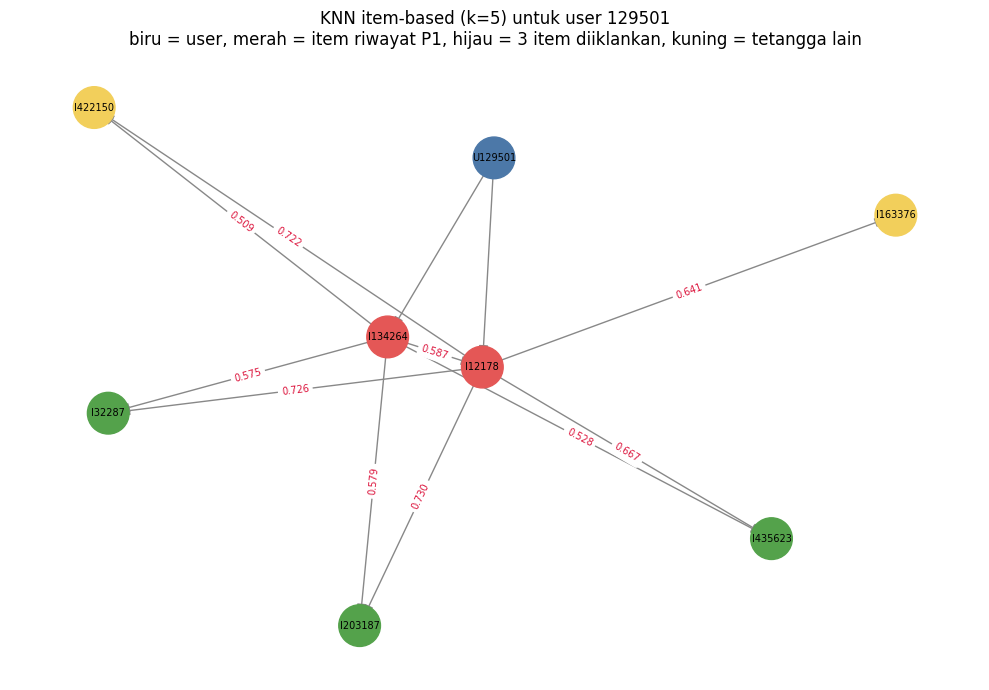

In [44]:
# visualisasi: user -> item riwayat -> tetangga KNN; hijau = item yang diiklankan
G_rek = nx.DiGraph()
u_node = f"U{USER}"
for item_asal in riwayat_user(USER):
    G_rek.add_edge(u_node, f"I{item_asal}", tipe="riwayat")
for r in jejak.itertuples():
    G_rek.add_edge(f"I{r.item_asal}", f"I{r.tetangga}", tipe="SIMILAR", score=r.cosine)

dipilih = {f"I{i}" for i in rekom["item"]}
asal = {f"I{i}" for i in riwayat_user(USER)}
warna = ["#4c78a8" if n == u_node else "#e45756" if n in asal else "#54a24b" if n in dipilih else "#f2cf5b"
         for n in G_rek.nodes()]

fig, ax = plt.subplots(figsize=(10, 7))
pos = nx.spring_layout(G_rek, seed=3, k=1.2)
nx.draw_networkx_nodes(G_rek, pos, node_color=warna, node_size=900, ax=ax)
nx.draw_networkx_labels(G_rek, pos, font_size=7, ax=ax)
nx.draw_networkx_edges(G_rek, pos, arrows=True, arrowsize=14, edge_color="#888", ax=ax)
nx.draw_networkx_edge_labels(
    G_rek, pos, font_size=7, font_color="crimson",
    edge_labels={(a, b): f"{d['score']:.3f}" for a, b, d in G_rek.edges(data=True) if d["tipe"] == "SIMILAR"},
    ax=ax)
ax.set_title(f"KNN item-based (k={K}) untuk user {USER}\n"
             "biru = user, merah = item riwayat P1, hijau = 3 item diiklankan, kuning = tetangga lain")
ax.axis("off")
plt.tight_layout()
plt.show()

#### No. 2 — Evaluasi Hit@5 dan NDCG@5

Item yang diiklankan dibandingkan dengan ground truth P2. Item dianggap **relevan** ($rel_p = 1$) jika user berinteraksi dengannya di P2 (view, addtocart, atau transaction).

$$\text{Hit@5} = \begin{cases} 1 & \text{jika ada item relevan di 5 posisi teratas} \\ 0 & \text{lainnya} \end{cases}$$

$$\text{DCG@5} = \sum_{p=1}^{5} \frac{rel_p}{\log_2(p+1)}, \qquad \text{IDCG@5} = \sum_{p=1}^{\min(|T|,\,5)} \frac{1}{\log_2(p+1)}, \qquad \text{NDCG@5} = \frac{\text{DCG@5}}{\text{IDCG@5}}$$

dengan $|T|$ = jumlah item ground truth. Karena daftar rekomendasi hanya berisi 3 item, posisi 4–5 kosong (dianggap tidak relevan).

In [45]:
def hit_at_k(rekomendasi, relevan, k=5):
    return int(any(item in relevan for item in rekomendasi[:k]))


def ndcg_at_k(rekomendasi, relevan, k=5):
    dcg = sum(1 / np.log2(p + 2) for p, item in enumerate(rekomendasi[:k]) if item in relevan)
    idcg = sum(1 / np.log2(p + 2) for p in range(min(len(relevan), k)))
    return dcg / idcg if idcg > 0 else 0.0


daftar_rekom = [int(i) for i in rekom["item"]]
relevan = truth_p2[USER]

rincian = pd.DataFrame({
    "posisi": range(1, 6),
    "item": pd.array(daftar_rekom + [None] * (5 - len(daftar_rekom)), dtype="Int64"),
})
rincian["relevan"] = [int(i in relevan) if pd.notna(i) else 0 for i in rincian["item"]]
rincian["diskon 1/log2(p+1)"] = 1 / np.log2(rincian["posisi"] + 1)
rincian["gain"] = rincian["relevan"] * rincian["diskon 1/log2(p+1)"]
print(rincian.round(4).to_string(index=False), "\n")

dcg5 = rincian["gain"].sum()
idcg5 = sum(1 / np.log2(p + 2) for p in range(min(len(relevan), 5)))
HIT5 = hit_at_k(daftar_rekom, relevan)
NDCG5 = ndcg_at_k(daftar_rekom, relevan)

print("Ground truth P2 :", sorted(relevan))
print(f"DCG@5  = {dcg5:.4f}")
print(f"IDCG@5 = {idcg5:.4f}")
print(f"Hit@5  = {HIT5}")
print(f"NDCG@5 = {NDCG5:.4f}")

 posisi   item  relevan  diskon 1/log2(p+1)  gain
      1 203187        0              1.0000   0.0
      2  32287        0              0.6309   0.0
      3 435623        0              0.5000   0.0
      4   <NA>        0              0.4307   0.0
      5   <NA>        0              0.3869   0.0 

Ground truth P2 : [134264]
DCG@5  = 0.0000
IDCG@5 = 1.0000
Hit@5  = 0
NDCG@5 = 0.0000


#### Diagnosis hasil

Untuk memahami hasil evaluasi, diperiksa posisi setiap item ground truth: apakah sudah pernah disentuh di P1 (sehingga sengaja dibuang dari rekomendasi), apakah item tersebut ada di graf P1, dan di peringkat berapa item tersebut muncul pada seluruh daftar kandidat KNN.

In [46]:
peringkat_kandidat = {item: p + 1 for p, (item, _) in enumerate(semua_kandidat)}
riwayat = riwayat_user(USER)

diagnosis = pd.DataFrame([{
    "item_ground_truth": t,
    "ada di graf P1": t in item_idx,
    "sudah disentuh di P1": t in riwayat,
    "jumlah visitor P1": int(deg_item[item_idx[t]]) if t in item_idx else 0,
    "peringkat di kandidat KNN": peringkat_kandidat.get(t, "tidak muncul"),
} for t in sorted(relevan)])
print("Jumlah seluruh kandidat KNN untuk user ini:", len(semua_kandidat))
diagnosis

Jumlah seluruh kandidat KNN untuk user ini: 5


,item_ground_truth,ada di graf P1,sudah disentuh di P1,jumlah visitor P1,peringkat di kandidat KNN
0,134264,True,True,10,tidak muncul


#### Evaluasi pada seluruh user yang layak

Hasil satu user sangat dipengaruhi kebetulan, sehingga metrik yang sama juga dihitung untuk **seluruh** user layak, dan dibandingkan dengan *baseline* **popularitas**: 3 item dengan visitor terbanyak di P1 yang belum disentuh user. Baseline ini adalah rekomendasi paling sederhana tanpa personalisasi.

In [47]:
populer = [int(item_ids[j]) for j in np.lexsort((item_ids, -deg_item))[:50]]


def rekomendasi_populer(user_id, n=N_REKOM):
    riwayat = riwayat_user(user_id)
    return [i for i in populer if i not in riwayat][:n]


hasil_eval = []
for u in user_layak:
    rel = truth_p2[u]
    knn_list = [int(i) for i in rekomendasi_knn(u)["item"]]
    pop_list = rekomendasi_populer(u)
    hasil_eval.append({
        "user": u,
        "hit_knn": hit_at_k(knn_list, rel), "ndcg_knn": ndcg_at_k(knn_list, rel),
        "hit_pop": hit_at_k(pop_list, rel), "ndcg_pop": ndcg_at_k(pop_list, rel),
        "truth_sudah_disentuh_P1": len(rel & set(riwayat_user(u))) / len(rel),
    })
hasil_eval = pd.DataFrame(hasil_eval)

ringkas_eval = pd.DataFrame({
    "Hit@5": [hasil_eval["hit_knn"].mean(), hasil_eval["hit_pop"].mean()],
    "NDCG@5": [hasil_eval["ndcg_knn"].mean(), hasil_eval["ndcg_pop"].mean()],
    "jumlah user hit": [hasil_eval["hit_knn"].sum(), hasil_eval["hit_pop"].sum()],
}, index=["Item-KNN (k=5)", "Popularitas"])
print(f"Rata-rata pada {len(hasil_eval)} user layak:")
print(f"- rata-rata proporsi item ground truth P2 yang sudah disentuh di P1: "
      f"{hasil_eval['truth_sudah_disentuh_P1'].mean():.1%}")
print(f"- user yang SEMUA item P2-nya sudah disentuh di P1 (kunjungan ulang): "
      f"{(hasil_eval['truth_sudah_disentuh_P1'] == 1).mean():.1%}")
ringkas_eval.round(4)

Rata-rata pada 3408 user layak:
- rata-rata proporsi item ground truth P2 yang sudah disentuh di P1: 30.2%
- user yang SEMUA item P2-nya sudah disentuh di P1 (kunjungan ulang): 25.5%


,Hit@5,NDCG@5,jumlah user hit
Item-KNN (k=5),0.0235,0.0112,80
Popularitas,0.0053,0.0014,18


**Kesimpulan 2.2**

**1. Rekomendasi menggunakan KNN**

Pemilihan user dilakukan secara acak menggunakan seed `42` agar hasilnya dapat direproduksi. User yang terpilih adalah visitor **129501**, dengan riwayat melihat item 134264 sebanyak 4 kali dan item 12178 sebanyak 1 kali pada periode P1.

Menggunakan item-based KNN dengan `k = 5`, skor rekomendasi dihitung berdasarkan nilai similarity dan frekuensi interaksi. Item yang sudah pernah dilihat oleh user tidak dimasukkan ke dalam rekomendasi.

Tiga item dengan skor tertinggi adalah sebagai berikut.

| Peringkat | Item | Skor |
|---|---:|---:|
| 1 | 203187 | 3,045 |
| 2 | 32287 | 3,026 |
| 3 | 435623 | 2,780 |

**2. Evaluasi rekomendasi**

Berdasarkan riwayat interaksi pada periode P2, user 129501 hanya kembali melihat item 134264 yang sebelumnya sudah dilihat pada P1. Karena item tersebut tidak dimasukkan ke dalam rekomendasi, tidak ada item rekomendasi yang cocok dengan ground truth.

- **Hit@5 = 0**, karena tidak ada item relevan yang berhasil direkomendasikan.
- **NDCG@5 = 0**, karena tidak ada item relevan yang ditemukan dalam daftar rekomendasi. Dengan satu item relevan pada ground truth, DCG@5 = 0 dan IDCG@5 = 1.